In [2]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, LeaveOneGroupOut

In [3]:
SEED = 42
np.random.seed(SEED)

# folder containing 'Person A' ... 'Person F'
DATA_ROOT = Path("data")

# folder for report figures
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# file names: g1=wave, g2=pinch, g3=swipe, g4=click
GESTURES = ["wave", "pinch", "swipe", "click"]  

# Load data

In [4]:
# Find all CSV files
paths = DATA_ROOT.glob("Person */*/*.csv")

# Loop over files
spectrograms, metadata_list = [], []
for path in paths:
    # Extract the person and gesture from the filename
    person, gesture = re.search(r"Person([A-Z])g(\d)s\d+\.csv$", path.name).groups()

    # Read the data (CSVs have no header row)
    x = pd.read_csv(path, header=None).to_numpy()
    spectrograms.append(x)

    # Store the info about the sample
    gesture_index = int(gesture) - 1
    metadata_list.append({
        "person": person,
        "label": gesture_index,
        "gesture": GESTURES[gesture_index]
    })

# Convert the meta info to a dataframe
metadata = pd.DataFrame(metadata_list)

In [5]:
# Show the data
print(f'Loaded {len(spectrograms)} spectrograms')
display(metadata.groupby(["person", "gesture"]).size().unstack())

Loaded 960 spectrograms


gesture,click,pinch,swipe,wave
person,,,,
A,40,40,40,40
B,40,40,40,40
C,40,40,40,40
D,40,40,40,40
E,40,40,40,40
F,40,40,40,40


# Data Exploration

In [6]:
# Check for missing (NaN) and infinite values
n_nan = sum(np.isnan(x).any() for x in spectrograms)
n_inf = sum(np.isinf(x).any() for x in spectrograms)

print(f"Samples with NaN: {n_nan}")
print(f"Samples with inf: {n_inf}")

Samples with NaN: 0
Samples with inf: 0


### Data shape
```spectograms``` is a list of N arrays
- each array represents one spectogram
- rows = Doppler bins (800 bins for each sample)
- cols = time bins (varying number of bins depending on gesture duration)
- values = magnitudes in dB

```metadata``` is a dataframe with one row per sample
each row contains the person and gesture

The ```metadata``` dataframe and ```spectograms``` list are aligned

In [7]:
# Shape of the data
n_doppler = np.unique([x.shape[0] for x in spectrograms])
n_time = np.array([x.shape[1] for x in spectrograms])

print(f"Doppler bins (rows):  {n_doppler}")
print(f"Time bins (columns):  min {n_time.min()}, max {n_time.max()}")
print(f"Value range [dB]:     min {min(x.min() for x in spectrograms):.1f}, max {max(x.max() for x in spectrograms):.1f}")
print(f"Example sample:       A spectrogram of shape {spectrograms[0].shape} -> {metadata.iloc[0].to_dict()}")

Doppler bins (rows):  [800]
Time bins (columns):  min 43, max 448
Value range [dB]:     min -121.3, max 0.0
Example sample:       A spectrogram of shape (800, 92) -> {'person': 'A', 'label': 3, 'gesture': 'click'}


**Interpretation:** 
- The spectograms in the dataset all have a fixed number of 800 doppler bins. 
- The number of time bins varies between a minimum of 43 and a maximum of 448 depending on the sample and the gesture.
- The magnitude values are normalized to their own maximum, so the max value is 0 dB.

#### Time bin distribution
The spectograms have been cropped to the length of the gesture. Therefore the samples have different lengths. Click gestures are shorter, while swipe gestures tend to be longer. Before training, the samples will have to be made uniform in their shape.

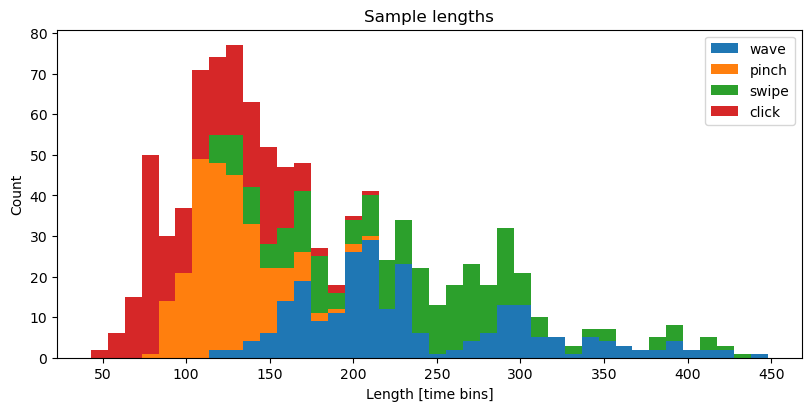

In [8]:
# Sample length = number of time bins (columns)
lengths = np.array([x.shape[1] for x in spectrograms])

# Plot stacked histogram of sample lengths per gesture
fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
ax.hist([lengths[metadata.gesture == g] for g in GESTURES], bins=40, stacked=True, label=GESTURES)
ax.set_title("Sample lengths")
ax.set_xlabel("Length [time bins]")
ax.set_ylabel("Count")
ax.legend()
fig.savefig(FIG_DIR / "length_histogram.pdf", bbox_inches="tight")
plt.show()

#### Magnitude distribution
Explain that there is noise in the lower magnitude values, while the gesture happens in the larger magnitude values. Is this relevant?

50th percentile: -37 dB
90th percentile: -21 dB
95th percentile: -17 dB
99th percentile: -9 dB


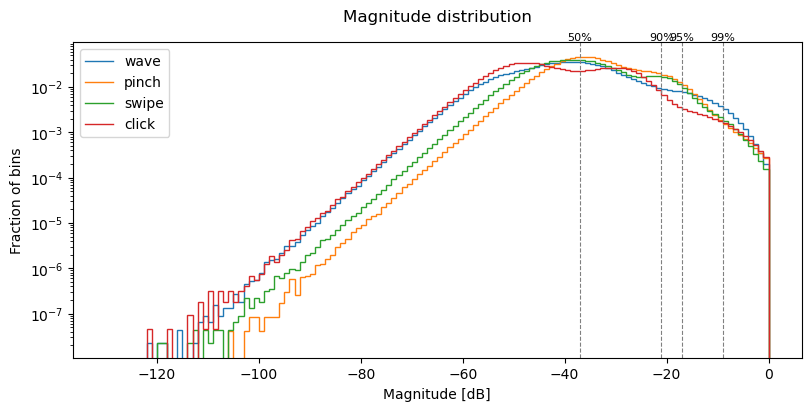

In [9]:
# Distribution of magnitude values (all time-Doppler bins) per gesture
# Accumulate histogram counts per sample to avoid stacking all values in memory
bins = np.linspace(-130, 0, 131)
all_counts = np.zeros(len(bins) - 1)

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
for g in GESTURES:
    counts = sum(np.histogram(spectrograms[i], bins=bins)[0] for i in metadata.index[metadata.gesture == g])
    all_counts += counts
    # Normalise to a fraction, since gestures differ in total number of bins
    ax.stairs(counts / counts.sum(), bins, label=g)

# Percentiles of all magnitude values, to choose the colour scale floor (vmin)
cdf = np.cumsum(all_counts) / all_counts.sum()
for p in [50, 90, 95, 99]:
    value = bins[1:][np.searchsorted(cdf, p / 100)]
    print(f"{p}th percentile: {value:.0f} dB")
    ax.axvline(value, color="gray", linestyle="--", linewidth=0.8)
    ax.text(value, 1, f"{p}%", transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=8)

ax.set_yscale("log")
ax.set_title("Magnitude distribution", pad=15)
ax.set_xlabel("Magnitude [dB]")
ax.set_ylabel("Fraction of bins")
ax.legend()
fig.savefig(FIG_DIR / "magnitude_histogram.pdf", bbox_inches="tight")
plt.show()

### Example plots

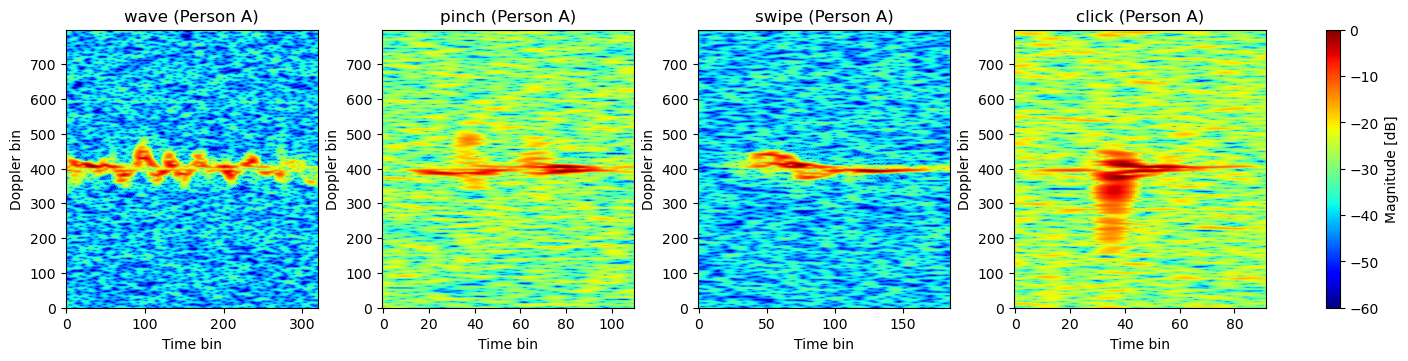

In [10]:
# Create four subplots
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5), constrained_layout=True)

# Loop over the gestures
for ax, g in zip(axes, GESTURES):
    i = metadata.index[metadata.gesture == g][0]

    # Show spectogram as image
    im = ax.imshow(spectrograms[i], aspect="auto", origin="lower", cmap="jet", vmin=-60, vmax=0)

    # Set title and labels
    ax.set_title(f"{g} (Person {metadata.person[i]})")
    ax.set_xlabel("Time bin")
    ax.set_ylabel("Doppler bin")

# Add a colorbar
fig.colorbar(im, ax=axes, label="Magnitude [dB]")

# Save the figure as pdf
fig.savefig(FIG_DIR / "spectrograms.pdf", bbox_inches="tight")
plt.show()

# Data split
The dataset is split into three roles: training, validation and test.

- The test set (20%) is separated first before any data (pre-)processing happens. This prevents data leakage from the test set into the training data. The test set is only used at the very end to evaluate the model performance. The split is stratified on person and gesture so every person-gesture combination has the same share in the test set.
- The training set (80%) contains the remaining data.
- Validation will be done with stratified 5-fold cross-validation. The training set is split into 5 folds. We train the model on 4 of the 5 folds and then evaluate its performance using the remaining 5th fold. This is repeated for every fold, so that each fold acts as test fold exactly once. The model and hyperparameters will be chosen based on the mean validation score over the folds. This way, no data is lost to validation and this provides a more reliable method than a single small validation set.

After picking the model and hyperparameters using the K-folds cross-validation, the model is retrained on the entire training set. Since this retraining now uses the data that was first used for validation (which influened the model choice). So the model is then tested on the test set that was set aside at the very beginning, which presents data the model has never seen before.

Additionally, it is interesting to see how well the model generalizes to new people. Therefore, additional validation is done by leaving one person out per fold. Since there are 6 persons (A through F), that means there will be 6 folds. This provides additional insight into the model performance.

So
1. Separate a 20% test set
2. Choose model and hyperparameters based on 5-fold cross-validation
3. Retrain the chosen model using the 6-fold LOSO (leave-one-subject-out) and report performance
4. Retrain the chosen model on all training data. This gives the final model
5. Evaluate the final model using the test set from the beginning.



In [11]:
# Extract the labels (gestures)
labels = metadata.label.to_numpy()

# Extract the persons
persons = metadata.person.to_numpy()

# Separate a test set
# Stratify on person and gesture
idx_train, idx_test = train_test_split(
    np.arange(len(metadata)),
    test_size=0.2,
    stratify=metadata.person + "_" + metadata.gesture,
    random_state=SEED,
)

# Create the K-fold splits of the training data
# Returns [(train1_idx, val1_idx), ..., (train5_idx, val5_idx)]
kfold = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(idx_train, labels[idx_train]))

# Create the LOSO folds
loso = list(LeaveOneGroupOut().split(idx_train, labels[idx_train], persons[idx_train]))

In [12]:
# Print the number of samples per set and the number of generated folds
print(f"Train:        {len(idx_train)}")
print(f"Test:         {len(idx_test)}")
print(f"k-fold folds: {len(kfold)}")
print(f"LOSO folds:   {len(loso)}")

# Show the split (this shows the stratifying worked)
split = np.where(
    np.isin(np.arange(len(metadata)), idx_test), 
    "test", 
    "train"
)
display(metadata.groupby([split, "gesture"]).size().unstack())

Train:        768
Test:         192
k-fold folds: 5
LOSO folds:   6


gesture,click,pinch,swipe,wave
test,48,48,48,48
train,192,192,192,192


# Data pre-processing

The spectrograms need three things before they can be used by a model: a fixed size, less noise, and a common value range. Every step below works on **each sample by itself with fixed constants**, so it can be applied to all samples without leaking information from the test set. The constants themselves (crop window, dB floor) are chosen by analysing the **training samples only** (`idx_train`).

Steps, in order:
1. Doppler crop: keep only the Doppler bins that contain the gesture
2. Dynamic-range floor: clip the background noise
3. Scaling: map the dB values to [0, 1]
4. Fixed size: make all samples the same shape

### 1. Doppler crop
Where along the Doppler axis is the gesture energy? The cell below computes the mean magnitude per Doppler bin, and which share of the strong values (above −10, −15 and −20 dB) falls inside candidate crop windows.

,bins 300-500,bins 250-550,bins 200-600
values above [dB],,,
-10,90.5%,97.2%,99.2%
-15,81.9%,90.3%,94.0%
-20,65.9%,76.0%,82.5%
-30,45.1%,56.7%,66.5%
-40,31.8%,44.3%,55.9%
-50,26.8%,39.4%,51.6%
-60,25.3%,37.8%,50.3%
-70,25.0%,37.5%,50.0%


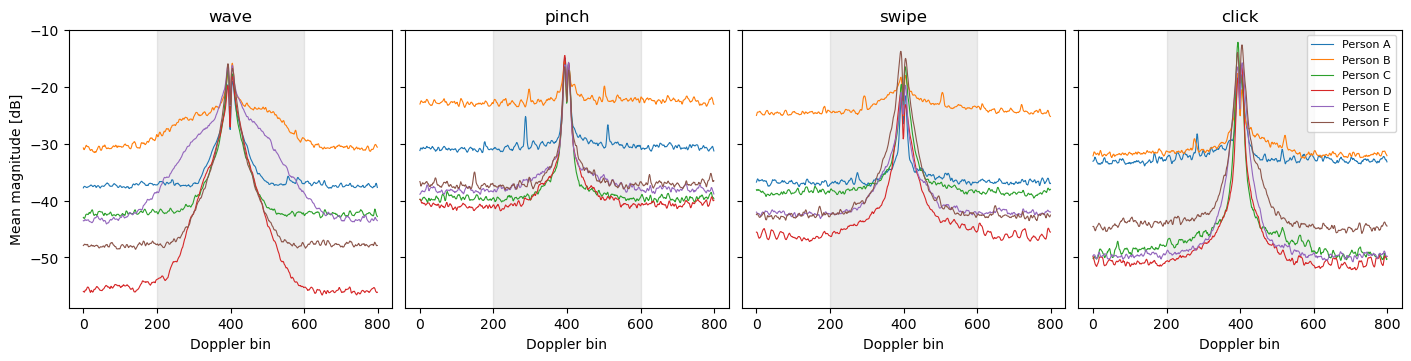

In [13]:
# Only use the training samples to choose the pre-processing constants
train_specs = [spectrograms[i] for i in idx_train]

# Share of strong values that falls inside each candidate crop window
windows = [(300, 500), (250, 550), (200, 600)]
rows = []
for threshold in [-10, -15, -20, -30, -40, -50, -60, -70]:
    strong = sum((x > threshold).sum(axis=1) for x in train_specs)
    strong = strong / strong.sum()
    row = {"values above [dB]": threshold}
    for lo, hi in windows:
        row[f"bins {lo}-{hi}"] = f"{strong[lo:hi].sum():.1%}"
    rows.append(row)
display(pd.DataFrame(rows).set_index("values above [dB]"))

# Plot the mean magnitude per Doppler bin: one subplot per gesture, one line per person
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5), sharey=True, constrained_layout=True)

for ax, g in zip(axes, GESTURES):
    for p in sorted(metadata.person.unique()):
        # Training samples of this gesture and person
        idx = idx_train[(metadata.gesture.to_numpy()[idx_train] == g) & (persons[idx_train] == p)]

        # Mean magnitude per Doppler bin, averaged over time and samples
        profile = np.mean([spectrograms[i].mean(axis=1) for i in idx], axis=0)
        ax.plot(profile, linewidth=0.8, label=f"Person {p}")

    # Mark the chosen crop window
    ax.axvspan(200, 600, color="gray", alpha=0.15)

    # Set title and labels
    ax.set_title(g)
    ax.set_xlabel("Doppler bin")

axes[0].set_ylabel("Mean magnitude [dB]")
axes[-1].legend(fontsize=8)

# Save the figure as pdf
fig.savefig(FIG_DIR / "doppler_profile.pdf", bbox_inches="tight")
plt.show()

**Results.**
- The profile is symmetric around Doppler bin 400. This is zero Doppler (no motion); bins above and below correspond to motion towards and away from the radar.
- Far from the centre the profile is flat at about −40 dB: there is only background noise there.
- The strong values are concentrated in the centre: 99.2% of the values above −10 dB lie within bins 200–600, 97.2% within 250–550 and 90.5% within 300–500.

**Options.**

| Option | Input size | Effect |
|---|---|---|
| No crop | 800 bins | Keeps everything, but half of the input is noise |
| **Crop to 200–600** | 400 bins | Keeps 99.2% of the strong signal, halves the input size |
| Crop to 300–500 | 200 bins | Smallest input, but loses ≈10% of the strong signal (the fastest motions) |

**Choice:** crop to Doppler bins 200–600. A smaller input means fewer parameters to learn, which matters with only 768 training samples.

### 2. Dynamic-range floor
The magnitude histogram showed a large mass of low values (background noise) and a thin tail of high values (the gesture). The cell below estimates the noise level in three ways: percentiles of all values, the mean magnitude far from zero Doppler, and the spread of the noise level between samples.

In [14]:
# Percentiles of all magnitude values in the training set (from accumulated 0.5 dB histograms)
bins = np.linspace(-130, 0, 261)
counts = sum(np.histogram(x, bins=bins)[0] for x in train_specs)
cdf = np.cumsum(counts) / counts.sum()
for p in [50, 75, 90, 95, 99]:
    print(f"{p}th percentile:              {bins[1:][np.searchsorted(cdf, p / 100)]:.1f} dB")

# Noise level far from zero Doppler (outside bins 150-650), where there is no gesture energy
noise_level = np.mean([np.concatenate([x[:150], x[650:]]).mean() for x in train_specs])
print(f"Mean magnitude outside 150-650: {noise_level:.1f} dB")

# Spread of the noise level between samples (median of each sample)
medians = np.array([np.median(x) for x in train_specs])
print(f"Per-sample median:              min {medians.min():.1f}, median {np.median(medians):.1f}, max {medians.max():.1f} dB")

50th percentile:              -37.0 dB
75th percentile:              -29.5 dB
90th percentile:              -21.5 dB
95th percentile:              -17.0 dB
99th percentile:              -9.0 dB
Mean magnitude outside 150-650: -39.8 dB
Per-sample median:              min -57.0, median -38.1, max -16.7 dB


**Results.**
- Half of all values are below −37 dB, and 75% are below −29.5 dB. Only 10% are above −21.5 dB.
- Far from zero Doppler, where there is no motion, the mean magnitude is −39.8 dB. This is the background noise level.
- The noise level differs a lot between samples: the per-sample median ranges from −57 to −17 dB.

**Options.**

| Option | Effect |
|---|---|
| No floor | Keeps all detail, but the model also has to learn to ignore noise down to −121 dB |
| Floor at −30 dB | Removes most noise, but also clips weak parts of the gesture (75% of all values are below −30 dB) |
| **Floor at −40 dB** | Clips everything at or below the background noise level, keeps the gesture |
| Floor at −50 dB | Mild; keeps much of the noise |
| Per-sample floor (e.g. at each sample's median) | Adapts to the varying noise level, but is harder to explain and changes the meaning of the dB values between samples |

Because every sample's peak is already at 0 dB, a floor at "peak − 40 dB" is the same as a fixed floor at −40 dB.

**Choice:** clip at −40 dB, the measured noise level. A fixed floor does not remove the extra noise in the noisiest samples; −30 and −50 dB are tested in the ablation.

### 3. Scaling
After the floor, all values lie in [−40, 0] dB.

| Option | Effect |
|---|---|
| **Fixed scaling (x + 40) / 40 → [0, 1]** | Fixed constants, so no statistics to fit and no leakage. Noise becomes 0, the peak becomes 1 |
| Per-sample min-max | Practically identical here, since every sample already spans [−40, 0] after the floor |
| Global z-score | Needs a mean and standard deviation fitted on the training folds only (inside a `Pipeline`), with no clear benefit over fixed scaling |

**Choice:** fixed scaling to [0, 1]. Neural networks train best on small inputs around 0–1, and noise at exactly 0 means "no signal".

### 4. Fixed size
The number of time bins depends on the gesture. The cell below shows the length distribution per gesture in the training set.

In [15]:
# Number of time bins per gesture (training set)
train_lengths = pd.Series([x.shape[1] for x in train_specs], name="time bins")
train_gestures = metadata.gesture.to_numpy()[idx_train]
display(train_lengths.groupby(train_gestures).describe()[["min", "25%", "50%", "75%", "max"]])

,min,25%,50%,75%,max
click,50.0,82.0,108.0,140.00,211.0
pinch,82.0,108.0,120.0,134.25,213.0
swipe,118.0,178.5,241.5,276.50,431.0
wave,116.0,188.5,217.5,290.25,427.0


**Results.** Median length in the training set: click 108, pinch 120, wave 218, swipe 242 time bins. The shortest training sample has 50 time bins, the longest 431. Click and pinch are short gestures; wave and swipe take about twice as long.

**Options.**

| Option | Pros | Cons |
|---|---|---|
| **Resize** (interpolate) the time axis to a fixed length, e.g. 128 | Keeps the whole gesture; no artificial padding | Stretches short gestures and squeezes long ones, so the duration is lost and the time scale differs between samples |
| Pad to the longest sample (≈450) with the floor value | Keeps the true time scale, so motion patterns are not distorted | Mostly empty input (most samples are 100–250 bins long); large input for a small dataset |
| Crop a fixed window around the energy peak | Same time scale for all samples, small input | Cuts off the start and end of long wave and swipe gestures |

**Choice.**
- **CNN:** resize the cropped spectrogram (400 Doppler bins × T time bins) to **128 × 128**. This is a small input for a small CNN, and every gesture is kept complete.
- **Classical models:** compute the features on the cropped, floored spectrogram at its **original length** (no resizing), and add the **duration** (number of time bins) as a feature. This gives back the duration information that resizing removes, and makes an interesting comparison with the CNN.
- Padding is tested as an alternative in the ablation.

### 5. Optional: data augmentation (CNN only)
Small random time shifts, slight time stretching and added noise create extra training variation. Augmentation is applied **only to the training part of each fold**, never to validation or test data. The Doppler axis is not flipped: that would reverse the direction of motion and change the gesture.

### Pre-processing function
The four steps combined in one function. With `out_shape=None` the resize step is skipped, which gives the input for feature extraction (original length).

In [16]:
from scipy.ndimage import zoom

# Pre-processing constants (chosen from the training-set analysis above)
DOPPLER_CROP = (200, 600)   # keep Doppler bins 200-599 around zero Doppler (bin 400)
DB_FLOOR = -40              # clip everything below the background noise level
OUT_SHAPE = (128, 128)      # (Doppler, time) input size for the CNN

def preprocess(x, crop=DOPPLER_CROP, floor=DB_FLOOR, out_shape=OUT_SHAPE):
    """Pre-process one spectrogram: Doppler crop, dB floor, scale to [0, 1], resize."""
    # 1. Doppler crop
    x = x[crop[0]:crop[1]]

    # 2. Dynamic-range floor
    x = np.maximum(x, floor)

    # 3. Scale [floor, 0] dB to [0, 1]
    x = (x - floor) / (0 - floor)

    # 4. Resize to a fixed shape (skipped if out_shape is None)
    if out_shape is not None:
        x = zoom(x, (out_shape[0] / x.shape[0], out_shape[1] / x.shape[1]), order=1)

    return x.astype(np.float32)

# Pre-process all samples
# Per-sample operation with fixed constants, so this does not leak test information
X_img = np.stack([preprocess(x) for x in spectrograms])

print(f"X_img: {X_img.shape}, values from {X_img.min():.2f} to {X_img.max():.2f}")

X_img: (960, 128, 128), values from 0.00 to 1.00


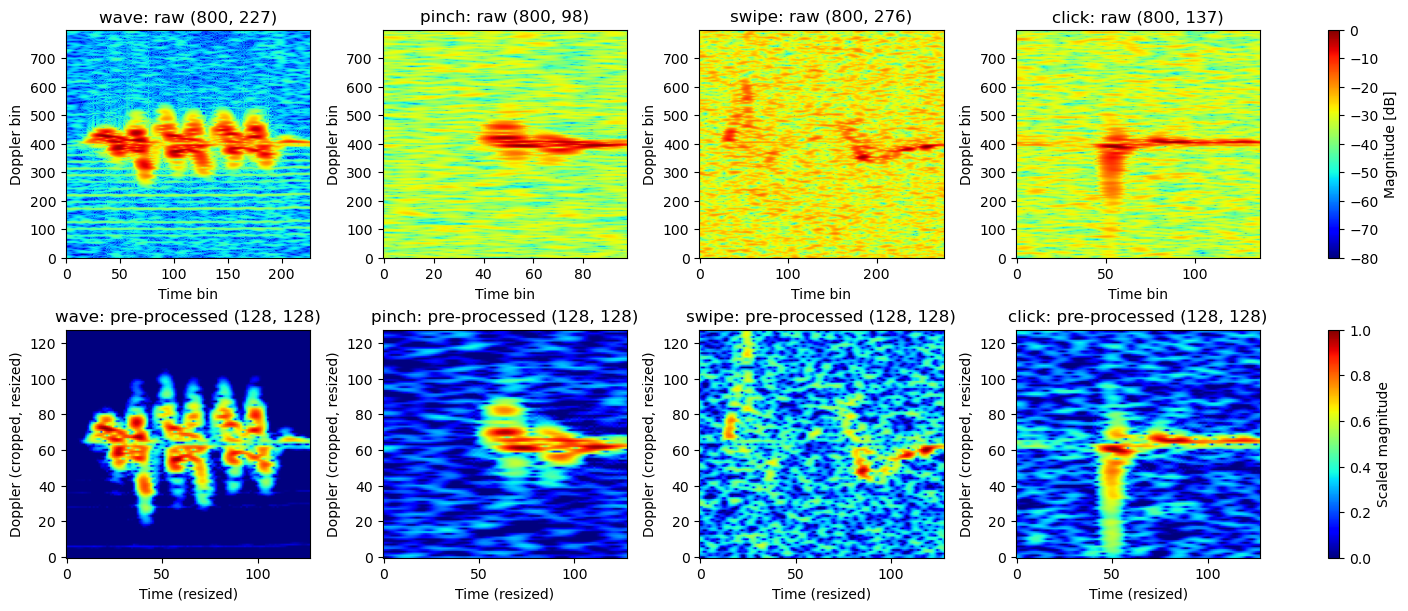

In [17]:
# Before / after pre-processing: one training sample per gesture
fig, axes = plt.subplots(2, 4, figsize=(14, 6), constrained_layout=True)

for j, g in enumerate(GESTURES):
    i = idx_train[labels[idx_train] == j][0]

    # Top row: raw spectrogram
    im_raw = axes[0, j].imshow(spectrograms[i], aspect="auto", origin="lower", cmap="jet", vmin=-80, vmax=0)
    axes[0, j].set_title(f"{g}: raw {spectrograms[i].shape}")
    axes[0, j].set_xlabel("Time bin")
    axes[0, j].set_ylabel("Doppler bin")

    # Bottom row: pre-processed spectrogram
    im_pre = axes[1, j].imshow(X_img[i], aspect="auto", origin="lower", cmap="jet", vmin=0, vmax=1)
    axes[1, j].set_title(f"{g}: pre-processed {X_img[i].shape}")
    axes[1, j].set_xlabel("Time (resized)")
    axes[1, j].set_ylabel("Doppler (cropped, resized)")

# Add a colorbar per row
fig.colorbar(im_raw, ax=axes[0], label="Magnitude [dB]")
fig.colorbar(im_pre, ax=axes[1], label="Scaled magnitude")

# Save the figure as pdf
fig.savefig(FIG_DIR / "preprocessing_before_after.pdf", bbox_inches="tight")
plt.show()

### Effect of each step (ablation)
*TODO once a first model exists:* measure the mean 5-fold validation accuracy of one fast model while adding the steps one at a time. This shows that each step helps, and tests the alternatives mentioned above.

| Variant | 5-fold accuracy (mean ± std) |
|---|---|
| Resize only | … |
| + Doppler crop 200–600 | … |
| + floor −40 dB | … |
| + scaling to [0, 1] | … |
| Floor −30 dB instead of −40 dB | … |
| Floor −50 dB instead of −40 dB | … |
| Padding instead of resizing | … |